In [2]:
import sys
sys.path.append('../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['p','o','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

depths = {"deepseek":61,
          "llama":32}

/tmp/ipykernel_2322822/2277556532.py:49: UserWarning: linewidths is ignored by contourf
  im0 = ax.contourf(B_layer_ids,
/tmp/ipykernel_2322822/2277556532.py:49: UserWarning: The following kwargs were not used by contour: 'rasterized'
  im0 = ax.contourf(B_layer_ids,


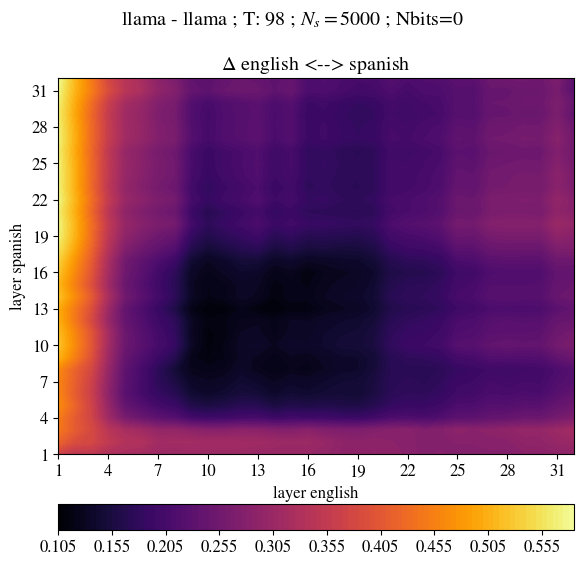

/tmp/ipykernel_2322822/2277556532.py:49: UserWarning: linewidths is ignored by contourf
  im0 = ax.contourf(B_layer_ids,
/tmp/ipykernel_2322822/2277556532.py:49: UserWarning: The following kwargs were not used by contour: 'rasterized'
  im0 = ax.contourf(B_layer_ids,


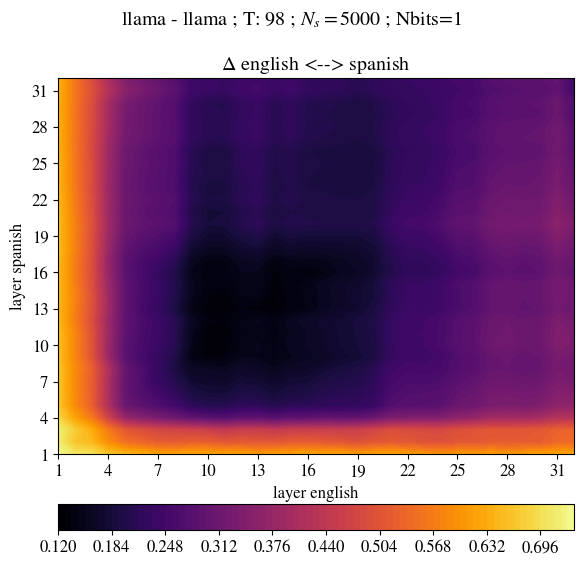

In [22]:
# model = 'deepseek'
model = 'llama'
mask = 2
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files
k = 10
n_tokens_list = [98]
avg = 0
Nbits_list = [0,1]
for Nbits_id,Nbits in enumerate(Nbits_list):
  for language_pair_id, language_pair in enumerate(language_pairs):
    for n_tokens in n_tokens_list:
      (languageA,languageB) = language_pair
      II_folder = makefolder(base=f'./results/santiago/',
                                model=model,
                                n_files=n_files,
                                languageA = languageA,
                                languageB = languageB,
                                mask = mask,
                                k = k,
                                Nbits = Nbits,
                                )
      IIAB = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_AB.npy')
      IIBA = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_BA.npy')
      IIs = np.array([IIAB,IIBA])*10

      cmap = 'inferno'
      # vmin = 0
      # vmax = 1 
      # levels = np.arange(0,1+eps,0.01)

      vmin = np.min(IIs)
      vmax = np.max(IIs)
      levels = 100

      A_layer_ids = np.arange(1,IIAB.shape[0]+1)
      B_layer_ids = np.arange(1,IIAB.shape[1]+1)
        

      fig,ax = plt.subplots(1,1,
                            figsize=(6,6),
                            # constrained_layout=True,
                            )
      # im0 = ax.contourf(B_layer_ids,A_layer_ids,IIs[0,:, :], levels=levels, vmin=vmin, vmax=vmax, cmap=cmap)
      im0 = ax.contourf(B_layer_ids,
                        A_layer_ids,
                        IIs[1], 
                        levels=levels, 
                        vmin=vmin, 
                        vmax=vmax, 
                        cmap=cmap,
                        linewidths=0,
                        rasterized=True,
                        antialiased=False)

      step = 3
      ax.set_xticks(ticks=A_layer_ids[::step], labels=A_layer_ids[::step])
      ax.set_yticks(ticks=B_layer_ids[::step], labels=B_layer_ids[::step])
      ax.set_xlabel(f'layer {languageA}')
      ax.set_ylabel(f'layer {languageB}')
      ax.set_title(r'$\Delta$' + f' {languageA} <--> {languageB}')

      cbar0 = fig.colorbar(im0, ax=ax, 
                            orientation='horizontal', 
                            pad=0.1)  # Adjust pad as needed
      # cbar0.set_ticks(np.arange(vmin,vmax+eps,(vmax-vmin)/10.))  # Define ticks
      im0.set_clim(vmin, vmax)  # Set color limits on the plot

      fig.suptitle(f'{model} - {model} ; T: {n_tokens} ; ' r'$N_s=$' f'{Ns} ; {Nbits=}' )
      fig.tight_layout()
      # fig.subplots_adjust(bottom=0.)
      plt.show()

      figsfolder = makefolder(base=f'./results/figs/translations/{model}',
                              create_folder=True,
                              n_files=n_files,
                              )

      fig.savefig(f'{figsfolder}{languageA}_{languageB}_{n_tokens}_Nbits_{Nbits}.png',
                  bbox_inches='tight',
                  dpi=300)

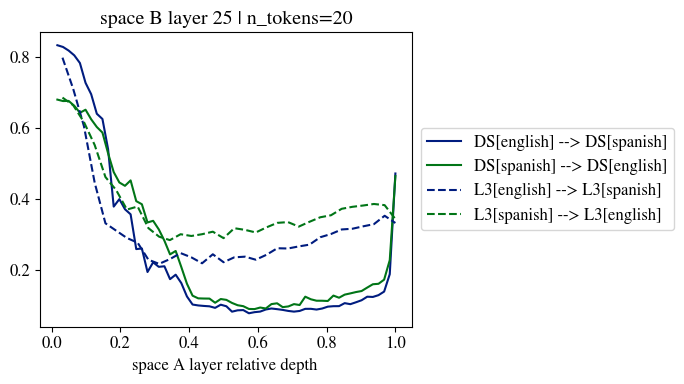

In [ ]:
models = ['deepseek','llama']
mask = 2
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [1,5,10,15,20,25,30,35,38]
n_tokens_list = [20]

for n_tokens_id,n_tokens in enumerate(n_tokens_list):
  fig,ax = plt.subplots(1,1,
                          figsize=(7,4),
                          # constrained_layout=True,
                          )
  for model_id,model in enumerate(models):
    if model == 'deepseek':
      _model = 'DS'
    elif model =='llama':
      _model = 'L3'

    for language_pair_id, language_pair in enumerate(language_pairs):

      (languageA,languageB) = language_pair
      II_folder = makefolder(base=f'./results/santiago/',
                                model=model,
                                n_files=n_files,
                                languageA=languageA,
                                languageB=languageB,
                                mask=mask,
                                )
      IIAB = np.load(II_folder + f'n_tokens_{n_tokens}_AB.npy')
      IIBA = np.load(II_folder + f'n_tokens_{n_tokens}_BA.npy')
      IIs = np.array([IIAB,IIBA])

      A_layer_ids = np.arange(1,IIAB.shape[0]+1)
      B_layer_ids = np.arange(1,IIAB.shape[1]+1)

      B_index = 3*IIAB.shape[0]//4
      ax.plot(A_layer_ids/IIAB.shape[0],
              IIs[0,B_index,:],
              label=f'{_model}[{languageA}] --> {_model}[{languageB}]',
              linestyle=_linestyles[model_id],
              color=colors[0],
              )
      ax.plot(A_layer_ids/IIAB.shape[0],
              IIs[1,B_index,:],
              label=f'{_model}[{languageB}] --> {_model}[{languageA}]',
              linestyle=_linestyles[model_id],
              color=colors[1],
              )

      figsfolder = makefolder(base=f'./results/figs/translations/',
                              create_folder=True,
                              n_files=n_files,
                              )
      box = ax.get_position()
      ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
      ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
      ax.set_xlabel('space A layer relative depth ')
      ax.set_title(f'space B layer {B_layer_ids[B_index]} | {n_tokens=}')
  fig.savefig(f'{figsfolder}translations_B_layer{B_layer_ids[B_index]}_{n_tokens}.pdf',
                bbox_inches='tight',
                )

### Diagonal

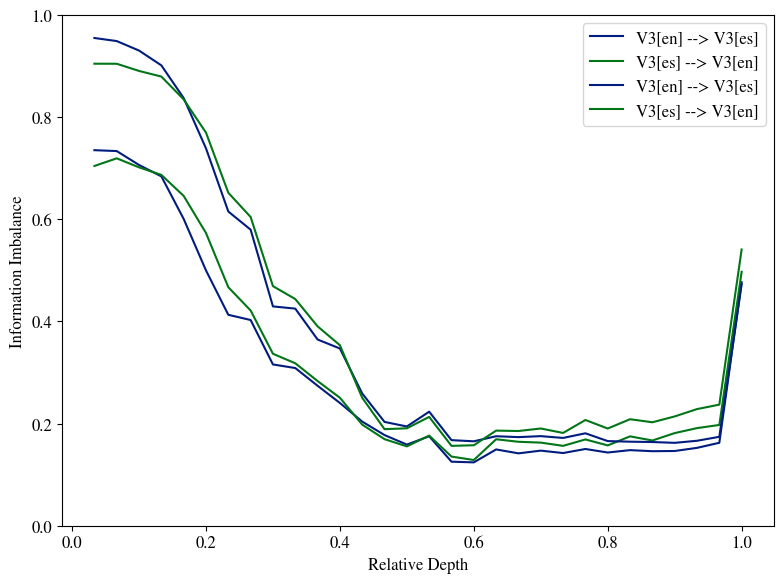

In [9]:
models = [
          'deepseek',
          # 'llama',
          ]
mask = 2
language_pairs = [('english','spanish'),
                  # ('english','italian'),
                  # ('spanish','italian'),
                  # ('german','hungarian'),
                  ]
n_files = 200

figsfolder = makefolder(base=f'./results/figs/translations/',
                        create_folder=True,
                        n_files=n_files,
                        )

batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [20]

fig,ax = plt.subplots(1,1,
                            figsize=(8,6),
                            # constrained_layout=True,
                            )

k_list = [10]
min_token_length = 40
Nbits_list = [0,1]

seed_list = [0]
batch_shuffle = 0
for Nbits_id, Nbits in enumerate(Nbits_list):
  for seed_id, seed in enumerate(seed_list):
    for k_id,k in enumerate(k_list):
      for avg in [0]:
        avg_tokens_II = avg
        avg_tokens_A = avg_tokens_II
        for n_tokens_id,n_tokens in enumerate(n_tokens_list):
          for model_id,model in enumerate(models):
            if model == 'deepseek':
              _model = 'V3'
            elif model =='llama':
              _model = 'L3'

            for language_pair_id, language_pair in enumerate(language_pairs):

              (languageA,languageB) = language_pair
              II_folder = makefolder(base=f'./results/santiago/',
                                    batch_shuffle=batch_shuffle,
                                    modelA=model,
                                    modelB=model,
                                    aux_A='source',
                                    aux_B='target',
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=languageA,
                                    languageB=languageB,
                                    mask=mask,
                                    k=k,
                                    Nbits=Nbits,
                                    seed=seed,
                                    )

              # alignment = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_A}_alignment.npy')
              II_AB = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_AB.npy')
              II_BA = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_BA.npy')

              IIs = np.array([II_AB,II_BA])

              A_layer_ids = np.arange(1,II_AB.shape[0]+1)

              ax.plot(A_layer_ids/II_AB.shape[0],
                      np.diagonal(IIs[0]),
                      label=f'{_model}[{get_acronym(languageA)}] --> {_model}[{get_acronym(languageB)}]',
                      linestyle=_linestyles[model_id],
                      color=colors[0],
                      )
              ax.plot(A_layer_ids/II_AB.shape[0],
                      np.diagonal(IIs[1]),
                      label=f'{_model}[{get_acronym(languageB)}] --> {_model}[{get_acronym(languageA)}]',
                      linestyle=_linestyles[model_id],
                      color=colors[1],
                      )
              # ax.plot(A_layer_ids/II_AB.shape[0],
              #         np.diagonal(alignment),
              #         label=f'A({_model}[{languageB}] <--> {_model}[{languageA}])',
              #         linestyle=_linestyles[model_id],
              #         color=colors[3],
              #         )
              # np.savetxt(figsfolder+f'{model}_{languageA}_{languageB}_{n_tokens}.txt',
              #           np.array([A_layer_ids,np.diagonal(IIs[0])]).T)
              # print(figsfolder+f'{model}_{languageA}_{languageB}_{n_tokens}')
              # np.savetxt(figsfolder+f'{model}_{languageB}_{languageA}_{n_tokens}.txt',
              #           np.array([A_layer_ids,np.diagonal(IIs[1])]).T)
            # np.savetxt(figsfolder+f'{model}_{languageA}_{languageB}_alignment_{n_tokens}.txt',
            #            np.array([A_layer_ids,np.diagonal(alignment)]).T)


          # box = ax.get_position()
          # ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
          # ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

          ax.set_xlabel('Relative Depth')
          ax.set_ylabel('Information Imbalance')
          ax.set_ylim(0,1)
          ax.legend(loc='upper right')
          # ax.set_title(f'{n_tokens=}')
  fig.savefig(f'{figsfolder}comparison_alignment_{n_tokens}.pdf',
                bbox_inches='tight',
                )
  # fig.savefig(f'{figsfolder}translations_diagonal_{n_tokens}.pdf',
  #               bbox_inches='tight',
  #               )

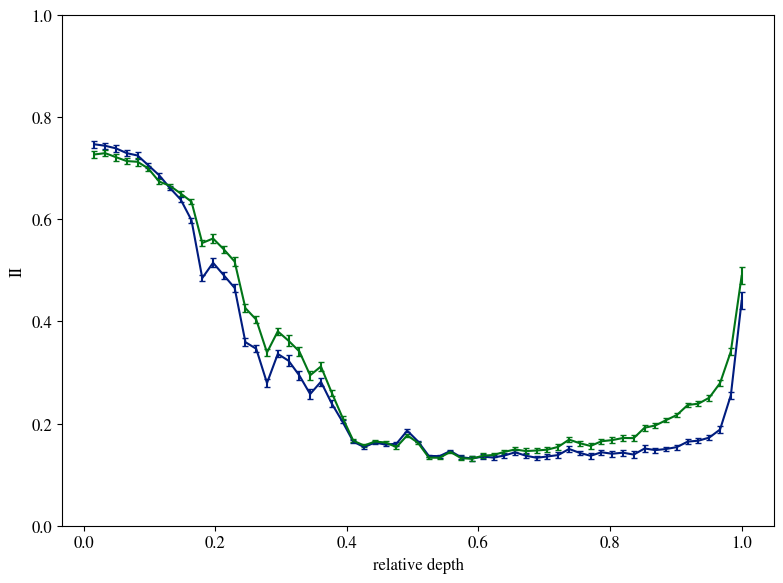

In [21]:
models = [
          'deepseek',
          # 'llama',
          ]
mask = 2
language_pairs = [('english','spanish'),
                  # ('german','hungarian'),
                  ]
n_files = 500
batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [20]

fig,ax = plt.subplots(1,1,
                            figsize=(8,6),
                            # constrained_layout=True,
                            )

k_list = [10]
min_token_length = 40
Nbits_list = [1]

seed_list = range(6)
IIs = np.zeros(shape=(len(seed_list),2,depths[model]))
for Nbits_id, Nbits in enumerate(Nbits_list):
  for k_id,k in enumerate(k_list):
    for avg in [0]:
      avg_tokens_II = avg
      avg_tokens_A = avg_tokens_II
      for n_tokens_id,n_tokens in enumerate(n_tokens_list):
        for model_id,model in enumerate(models):
          A_layer_ids = np.arange(1,depths[model]+1)
          B_layer_ids = np.arange(1,depths[model]+1)

          if model == 'deepseek':
            _model = 'V3'
          elif model =='llama':
            _model = 'L3'
          for language_pair_id, language_pair in enumerate(language_pairs):
            for seed_id, seed in enumerate(seed_list):
              (languageA,languageB) = language_pair
              II_folder = makefolder(base=f'./results/santiago/',
                                        modelA=model,
                                        modelB=model,
                                        n_files=n_files,
                                        min_token_length=min_token_length,
                                        languageA=languageA,
                                        languageB=languageB,
                                        mask=mask,
                                        k=k,
                                        Nbits=Nbits,
                                        seed=seed,
                                        )
              alignment = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_A}_alignment.npy')
              IIs[seed_id,0,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_AB.npy').diagonal()
              IIs[seed_id,1,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_BA.npy').diagonal()

            ax.errorbar(A_layer_ids/depths[model],
                      IIs[:,0,:].mean(axis=0),
                      IIs[:,0,:].std(axis=0),
                      label=f'{_model}[{get_acronym(languageA)}] --> {_model}[{get_acronym(languageB)}]',
                      linestyle=_linestyles[model_id],
                      color=colors[0],
                      capsize=2,
                      )
            ax.errorbar(A_layer_ids/depths[model],
                      IIs[:,1,:].mean(axis=0),
                      IIs[:,0,:].std(axis=0),
                      label=f'{_model}[{get_acronym(languageB)}] --> {_model}[{get_acronym(languageA)}]',
                      linestyle=_linestyles[model_id],
                      color=colors[1],
                      capsize=2,
                      )
          figsfolder = makefolder(base=f'./results/figs/translations/',
                                  create_folder=True,
                                  n_files=n_files,
                                  )
          
          # np.savetxt(figsfolder+f'{model}_{languageA}_{languageB}_{n_tokens}.txt',
          #            np.array([A_layer_ids,np.diagonal(IIs[0])]).T)
          # np.savetxt(figsfolder+f'{model}_{languageB}_{languageA}_{n_tokens}.txt',
          #            np.array([A_layer_ids,np.diagonal(IIs[1])]).T)
          # box = ax.get_position()
          # ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
          # ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

          ax.set_xlabel('relative depth')
          ax.set_ylabel('II')
          ax.set_ylim(0,1)
          # ax.legend(loc='lower left')
          # ax.set_title(f'{n_tokens=}')
  fig.savefig(f'{figsfolder}translations_diagonal_{n_tokens}.pdf',
                bbox_inches='tight',
                )